In [1]:
suppressPackageStartupMessages({
library(ArchR)
library(tidyverse)
})
    
addArchRThreads(threads = 30) 


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

In [2]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'

p_output <- paste0(work_dir,  'DARs_archr/')
dir.create(p_output, recursive = T)

In [3]:
## Load project
proj <- loadArchRProject('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/proj_immnk_tfpilot_ipsc/')

Successfully loaded ArchRProject!


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .____

In [4]:
proj


           ___      .______        ______  __    __  .______      
          /   \     |   _  \      /      ||  |  |  | |   _  \     
         /  ^  \    |  |_)  |    |  ,----'|  |__|  | |  |_)  |    
        /  /_\  \   |      /     |  |     |   __   | |      /     
       /  _____  \  |  |\  \\___ |  `----.|  |  |  | |  |\  \\___.
      /__/     \__\ | _| `._____| \______||__|  |__| | _| `._____|
    



class: ArchRProject 
outputDirectory: /lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/proj_immnk_tfpilot_ipsc 
samples(1): multi_Imm_NK15385635
sampleColData names(1): ArrowFiles
cellColData names(20): Sample TSSEnrichment ... ReadsInPeaks FRIP
numberOfCells(1): 5800
medianTSS(1): 9.8135
medianFrags(1): 13358.5

In [5]:
## Read cells used in the analysis (and subset)
cell_anno <- read_csv('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/seacells_gex/tf_pilot/batch1/ipsc/cell_anno_with_seacells.csv')

New names:
• `` -> `...1`
Rows: 5400 Columns: 170
── Column specification ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr  (38): ...1, rna:sample_barcode, rna:barcode, rna:gex_barcode, rna:atac_...
dbl (129): rna:cellranger_gex_umis_count, rna:cellranger_gex_genes_count, rn...
lgl   (3): rna:amulet_doublet, atac:amulet_doublet, amulet_doublet

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [6]:
nrow(cell_anno)

[1] 5400

In [7]:
length(unique(cell_anno$sample_barcode))

[1] 5400

In [8]:
length(proj$cellNames[proj$sample_barcode %in% cell_anno$sample_barcode])

[1] 5061

In [9]:
## Subset to cells of interest
proj <- subsetCells(proj, cellNames =proj$cellNames[proj$sample_barcode %in% cell_anno$sample_barcode])

In [10]:
sort(table(proj$perturbation), decreasing = T)


   HOPX    TCF7 Control   TBX21   FOXO3   CEBPD   RUNX2   PRDM1    EBF1 
    932     931     802     550     543     442     311     280     270 

In [31]:
## Calling marker peaks based on the peak-groups
markersPeaks <- getMarkerFeatures(
    ArchRProj = proj, 
    useMatrix = "PeakMatrix", 
    groupBy = "perturbation",
    bgdGroups = c("Control"),
    bias = c("TSSEnrichment", "log10(nFrags)"),
    testMethod = "wilcoxon"
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-194e1e208675f0-Date-2026-05-10_Time-20-48-37.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2026-05-10 20:48:37 : Matching Known Biases, 0.002 mins elapsed.

###########
2026-05-10 20:51:04 : Completed Pairwise Tests, 2.449 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-194e1e208675f0-Date-2026-05-10_Time-20-48-37.log



In [54]:
saveRDS(markersPeaks, paste0(p_output, '/archr_DARs_perturbation_obj.rds'))

In [44]:
## Extract markers
markerList <- getMarkers(markersPeaks, cutOff = "FDR <= 0.05 & Log2FC >= 0.5")
markerList

List of length 9
names(9): CEBPD Control EBF1 FOXO3 HOPX PRDM1 RUNX2 TBX21 TCF7

In [45]:
markerPeaks_df <- Reduce(bind_rows,lapply(1:length(markerList), function(i) {
  ## Cell type or state
  ct <- names(markerList)[i]
  ## Object of marker peaks
  gr <- markerList[[i]]
  if (nrow(gr) == 0) {
    return(NULL)
  } else {
     ## Getting peak names and stats
    peaks <- data.frame(chr=as.character(gr$seqnames), 
                        start=gr$start,
                        end=gr$end,
                        Log2FC=gr$Log2FC,
                        FDR=gr$FDR,
                        MeanDiff=gr$MeanDiff,
                        Cell_type=ct,
                        stringsAsFactors = F) %>%
      mutate(peak=paste0(chr, ':',start, '-',end))
    return(peaks)
  }
}))

In [46]:
head(markerPeaks_df)

,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,chr5,160293835,160294335,2.724173,4.305581e-02,0.3240784,CEBPD,chr5:160293835-160294335
2,chr19,38213713,38214213,6.875422,1.254901e-05,0.4693987,RUNX2,chr19:38213713-38214213
3,chr1,24964880,24965380,5.539634,2.720876e-05,0.4093567,RUNX2,chr1:24964880-24965380
4,chr11,7576003,7576503,6.712729,2.720876e-05,0.4189101,RUNX2,chr11:7576003-7576503
5,chr5,149001995,149002495,3.329944,2.720876e-05,0.5041032,RUNX2,chr5:149001995-149002495
6,chr8,1059445,1059945,4.265508,2.720876e-05,0.4177002,RUNX2,chr8:1059445-1059945


In [47]:
nrow(markerPeaks_df)

[1] 743

In [48]:
tail(markerPeaks_df, n=60)

,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
684,chr22,20100483,20100983,5.428071,4.165089e-02,0.16957200,RUNX2,chr22:20100483-20100983
685,chr22,31243901,31244401,3.653154,4.165089e-02,0.23059829,RUNX2,chr22:31243901-31244401
686,chr22,36461942,36462442,4.208599,4.165089e-02,0.34494125,RUNX2,chr22:36461942-36462442
687,chr22,37279452,37279952,3.250173,4.165089e-02,0.26107091,RUNX2,chr22:37279452-37279952
688,chr22,39448005,39448505,4.936307,4.165089e-02,0.11942736,RUNX2,chr22:39448005-39448505
689,chr3,123818421,123818921,4.726640,4.165089e-02,0.10272777,RUNX2,chr3:123818421-123818921
690,chr3,149142636,149143136,5.239427,4.165089e-02,0.14829341,RUNX2,chr3:149142636-149143136
691,chr3,167941530,167942030,5.508393,4.165089e-02,0.17951166,RUNX2,chr3:167941530-167942030
692,chr4,5012115,5012615,5.304889,4.165089e-02,0.15536438,RUNX2,chr4:5012115-5012615


In [49]:
sort(table(markerPeaks_df$Cell_type), decreasing=T)


RUNX2 TBX21 CEBPD 
  731    11     1 

In [50]:
## Plot heatmap
heatmapGS <- plotMarkerHeatmap(
  seMarker = markersPeaks, 
  cutOff = "FDR <= 0.05 & Log2FC >= 0.5", 
  transpose = FALSE,
  binaryClusterRows = T, 
  clusterCols = T,
  nLabel = 3,
  nPrint = 3
)

ArchR logging to : ArchRLogs/ArchR-plotMarkerHeatmap-194e1e6d36ccd6-Date-2026-05-10_Time-20-55-45.log
If there is an issue, please report to github with logFile!

Identified 743 markers!



[1] "chr5:160293835-160294335"  "chr1:8427548-8428048"     
[3] "chr1:8626304-8626804"      "chr1:12075618-12076118"   
[5] "chr1:48500501-48501001"    "chr10:104349592-104350092"
[7] "chr11:15622355-15622855"  


Preparing Main Heatmap..

'magick' package is suggested to install to give better rasterization.

Set `ht_opt$message = FALSE` to turn off this message.

ArchR logging successful to : ArchRLogs/ArchR-plotMarkerHeatmap-194e1e6d36ccd6-Date-2026-05-10_Time-20-55-45.log



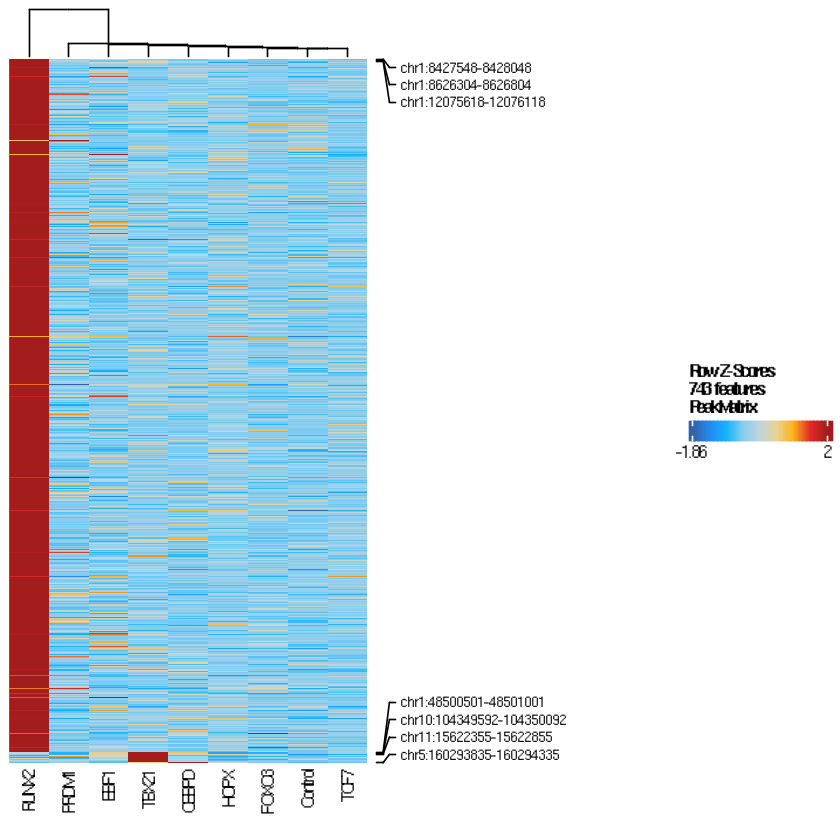

In [51]:
heatmapGS

In [52]:
pdf(paste0(p_output, 'archr_DARs_perturbation.pdf'), width =10, height = 8); draw(heatmapGS, heatmap_legend_side = "bot", annotation_legend_side = "bot");dev.off()


png 
  2

In [53]:
write_tsv(markerPeaks_df, paste0(p_output, 'archr_DARs_perturbation_df.txt'))

In [55]:
sessionInfo()

R version 4.1.2 (2021-11-01)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /software/conda/users/od5/archr/lib/libopenblasp-r0.3.28.so

Random number generation:
 RNG:     L'Ecuyer-CMRG 
 Normal:  Inversion 
 Sample:  Rejection 
 
locale:
 [1] LC_CTYPE=en_GB.utf8       LC_NUMERIC=C             
 [3] LC_TIME=en_GB.utf8        LC_COLLATE=en_GB.utf8    
 [5] LC_MONETARY=en_GB.utf8    LC_MESSAGES=en_GB.utf8   
 [7] LC_PAPER=en_GB.utf8       LC_NAME=C                
 [9] LC_ADDRESS=C              LC_TELEPHONE=C           
[11] LC_MEASUREMENT=en_GB.utf8 LC_IDENTIFICATION=C      

attached base packages:
 [1] parallel  stats4    grid      stats     graphics  grDevices utils    
 [8] datasets  methods   base     

other attached packages:
 [1] circlize_0.4.15             ComplexHeatmap_2.10.0      
 [3] nabor_0.5.0                 forcats_1.0.0              
 [5] dplyr_1.1.4                 purrr_0.3.4                
 [7] r